In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from dispersionrelations.integrals import OmnesFunction

import sphysics

# Omnès function for the $\pi\pi$ S-wave, $I=2$

This notebook shows the isospin-2 $\pi\pi$ S-wave Omnès function constructed from the corresponding phase shift $\delta_0^2(s)$.

The code for the phase shift and the Omnès function, including this notebook, comes from Leon Heuser <heuser@hiskp.uni-bonn.de>.

Given an elastic phase shift $\delta(s)$ above threshold $s_\text{thr}=4M_\pi^2$, the Omnès function

$$
\Omega(s) = \exp\left(\frac{s}{\pi}\int_{s_\text{thr}}^{\infty}\frac{\delta(x)\,\mathrm{d}x}{x\,(x-s-i\epsilon)}\right)
$$

is the unique function that is analytic in the complex $s$-plane except for the right-hand cut, carries exactly the phase $\delta(s)$ along that cut ($\arg\Omega(s+i\epsilon)=\delta(s)$), and is normalised to $\Omega(0)=1$.

A form factor with two-body final-state interactions then reads
$$
F(s)=P(s)\,\Omega(s)
$$
with a polynomial $P(s)$.

**All quantities are in GeV** (the package's unit convention).

## 1. Input: the $I=2$ S-wave $\pi\pi$ phase shift

$\delta_0^2$ is repulsive (negative) and has no resonance. Up to $\sqrt{s_c}=2.1$ GeV we use the parametrisation of [Peláez, Rabán, Ruiz de Elvira, *Phys. Rev. D* **111** (2025) 074003](https://inspirehep.net/literature/2861868) (cubic term $\hat B_3$, $\sqrt{s_h}=2.3$ GeV, fit range up to 2.1 GeV). Above $s_c$ the phase is continued smoothly to zero with an ad-hoc $1/s$ fall-off, which is not part of the published parametrisations. The three pieces, with $k=\sqrt{s/4-M_\pi^2}$ and the conformal variable

$$
w(s;s_0)=\frac{\sqrt{s}-\sqrt{s_0-s}}{\sqrt{s}+\sqrt{s_0-s}} .
$$

| region | form |
|---|---|
| $\sqrt{s}<0.85$ GeV | $\cot\delta = \dfrac{\sqrt{s}}{2k}\,\dfrac{M_\pi^2}{s-2z_2^2}\,\big[B_0+B_1\,w(s;s_l)\big]$, $\quad\sqrt{s_l}=1.05$ GeV |
| $0.85<\sqrt{s}<2.1$ GeV | same prefactor, polynomial $\sum_{i=0}^{3}\hat B_i\,\big[w(s;s_h)-w(s_m;s_h)\big]^i$, $\quad\sqrt{s_m}=0.85,\ \sqrt{s_h}=2.3$ GeV |
| $\sqrt{s}>2.1$ GeV | $\delta(s)=\delta_0+(\delta(s_c)-\delta_0)\,\dfrac{\lambda+s_c}{\lambda+s}$, $\quad\sqrt{s_c}=2.1$ GeV |

The factor $s-2z_2^2$ places the Adler zero (below threshold) at $s=2z_2^2$.

 $\hat B_0,\hat B_1$ are fixed by matching the low-energy form at $s_m$; 
 
 $\delta(s_c)$ and $\lambda$ are fixed by continuity of $\delta$ and $\delta'$ at $s_c$, so that $\delta\to \delta_0$ (=0 for $S2$) for $s\to\infty$. 
 
 
 The free parameters are $B_0, B_1, z_2, \hat B_2, \hat B_3$. Taken from the Global II values of [Pelaez:2024uav](https://inspirehep.net/literature/2861868)

See [`piPiSwaveI2_phaseShiftS`](#sphysics.amplitudes.resonance.piPiSwaveI2_phaseShiftS) for the documentation of the phase shift implemented in sphysics.

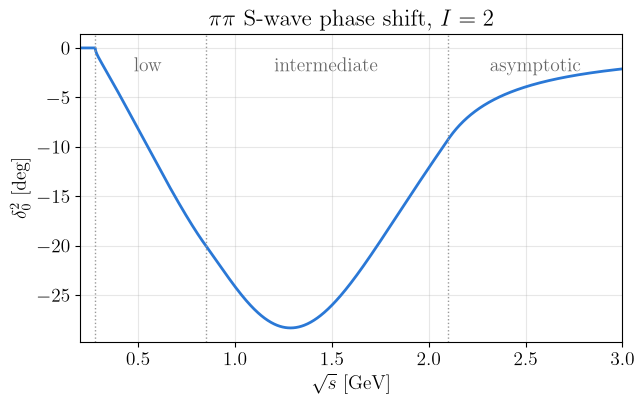

In [2]:
E = np.linspace(0.2, 3.0, 1000)          # sqrt(s) [GeV]
s = E**2

phase_shift = sphysics.amplitudes.resonance.piPiSwaveI2_phaseShiftS(s)

S_THR = 4 * sphysics.Constants.M.pi**2
SQ_SM, SQ_SINF = 0.85, 2.1

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(E, np.degrees(phase_shift), color="#2a78d6", lw=2)
for x in (S_THR**0.5, SQ_SM, SQ_SINF):
    ax.axvline(x, color="0.6", lw=1, ls=":")
for x, label in [(0.55, "low"), (1.47, "intermediate"), (2.55, "asymptotic")]:
    ax.text(x, -1, label, ha="center", va="top", color="0.4")
ax.set(xlabel=r"$\sqrt{s}$ [GeV]", ylabel=r"$\delta_0^2$ [deg]", xlim=(E[0], E[-1]),
       title=r"$\pi\pi$ S-wave phase shift, $I=2$")
ax.grid(alpha=0.3)
plt.show()

## 2. The Omnès function

`OmnesFunction` takes any callable phase $\delta(s)$ and the threshold. The remaining arguments control the numerics and the subtraction:

- `subtraction_point=0`, `subtraction_constants=[0]`: one subtraction at $s=0$ with $\log\Omega(0)=0$, i.e. $\Omega(0)=1$ (the formula above).
- `infinity`, `integration_split_points` (in units of the threshold) and `integration_order`: the Gauss–Legendre grid for the dispersion integral. The phase is evaluated on that grid **once** when the object is created; calling it afterwards is fast and vectorised.

The principal value on the cut is handled analytically, so real $s$ above threshold returns the boundary value $\Omega(s+i\epsilon)$. Complex $s$ works as well.

The Omnès function is built from the phase shift alone, i.e. it assumes elastic $\pi\pi$ scattering (Watson's theorem). The Global II fit of Peláez et al. to the scarce inelasticity data gives a sizeable $I=2$ S-wave inelasticity above $0.915$ GeV, $\eta_0^2(s)=1-\epsilon(1-\hat s/s)^{3/2}$ with $\epsilon\approx0.33$ ($\eta_0^2\approx0.91$ at 1.2 GeV, $\approx0.76$ at 2.1 GeV), which is neglected here.

See [`piPiSwaveI2_omnesS`](#sphysics.amplitudes.resonance.piPiSwaveI2_omnesS) for the documentation of the Omnès function provided by sphysics.

In [3]:
omnes_S2 = OmnesFunction(
    sphysics.amplitudes.resonance.piPiSwaveI2_phaseShiftS,
    threshold=S_THR,
    infinity=1e6,
    integration_split_points=[2, 5, 10, 50, 100, 1000],
    integration_order=100,
    subtraction_point=0.0,
    subtraction_constants=[0.0],
)

# or directly from sphysics
omega = sphysics.amplitudes.resonance.piPiSwaveI2_omnesS(s)

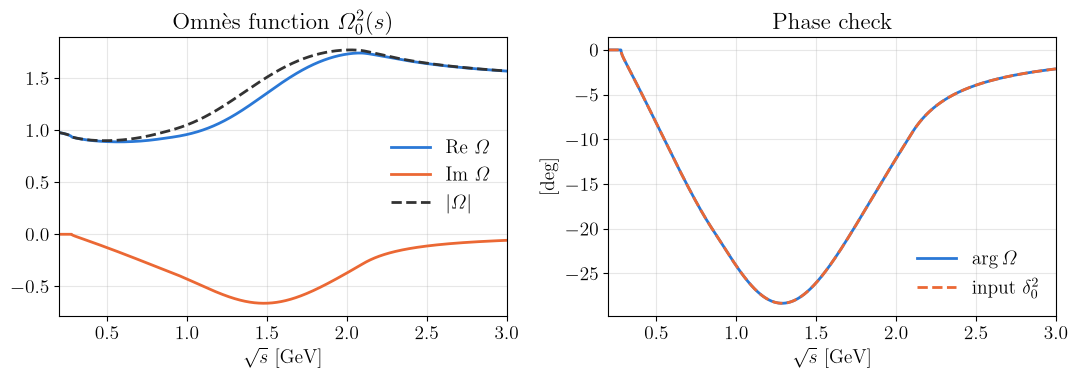

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

ax1.plot(E, omega.real, color="#2a78d6", lw=2, label=r"Re $\Omega$")
ax1.plot(E, omega.imag, color="#eb6834", lw=2, label=r"Im $\Omega$")
ax1.plot(E, np.abs(omega), color="0.2", lw=2, ls="--", label=r"$|\Omega|$")
ax1.set(xlabel=r"$\sqrt{s}$ [GeV]", title=r"Omnès function $\Omega_0^2(s)$")
ax1.legend(frameon=False)

ax2.plot(E, np.degrees(np.angle(omega)), color="#2a78d6", lw=2, label=r"$\arg\Omega$")
ax2.plot(E, np.degrees(phase_shift), color="#eb6834", lw=2, ls="--", label=r"input $\delta_0^2$")
ax2.set(xlabel=r"$\sqrt{s}$ [GeV]", ylabel="[deg]", title="Phase check")
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.axvline(0, color="0.6", lw=1, ls=":")
    ax.grid(alpha=0.3)
ax1.set_xlim(E[0], E[-1])
plt.tight_layout()
plt.show()